# Alternative Macro Economic Indices API — Crisis Similarity & Macro Regime Backtest

Quantitative macro regime analytics and cross-asset backtesting using the **Alternative Macro Economic Indices API (v1.2.0)** (`https://alternative-macro-economic-indices.p.rapidapi.com`).

- **Endpoints Covered:** `/v1/crisis-similarity` (`ULTRA`), `/v1/regime-summary` (`PRO` / `ULTRA`), `/v1/batch` (`ULTRA`), and `/v1/categories/manufacturing` (`PRO`).
- **Zero Synthetic Data Policy:** All regime classifications, cosine similarity alignments, Big Mac PPP valuations, and 13-month macro deltas are computed strictly from real gateway payloads without fabricated equity returns or zero-filled missing drivers.
- **Note on `DEMO_MODE`:** `examples/responses/crisis-similarity.json` captures `window=latest`. Historical `month`/`asOf` `/v1/crisis-similarity` queries require a live `ULTRA` `RAPIDAPI_KEY`; the 13-month historical regime backtest below uses the bundled `category-manufacturing.json` and `batch-commodities.json` time series.


In [1]:
import json
import os
import sys
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules

def resolve_responses_dir() -> Path | None:
    candidates = [
        Path("examples/responses"),
        Path("../examples/responses"),
        Path("altmacro-quant-api/examples/responses"),
    ]
    for cand in candidates:
        if cand.is_dir() and (cand / "health.json").is_file():
            return cand.resolve()
    return None

RESPONSES_DIR = resolve_responses_dir()

if IN_COLAB and RESPONSES_DIR is None:
    repo_dir = Path("altmacro-quant-api")
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", "https://github.com/nkcDuck/altmacro-quant-api.git"],
            check=True,
        )
    RESPONSES_DIR = resolve_responses_dir()

try:
    import requests
except ImportError:
    requests = None

RAPIDAPI_HOST = "alternative-macro-economic-indices.p.rapidapi.com"
BASE_URL = f"https://{RAPIDAPI_HOST}"

RAPIDAPI_KEY = os.environ.get("RAPIDAPI_KEY", "").strip()
if not RAPIDAPI_KEY and IN_COLAB:
    try:
        from google.colab import userdata  # type: ignore
        RAPIDAPI_KEY = (userdata.get("RAPIDAPI_KEY") or "").strip()
    except Exception:
        pass

ENV_DEMO = os.environ.get("DEMO_MODE", "").strip().lower() in {"1", "true", "yes"}
DEMO_MODE = ENV_DEMO or (not RAPIDAPI_KEY)

def api_get(endpoint_path: str, fallback_file: str, params: dict | None = None) -> dict:
    """Fetch from RapidAPI Proxy when RAPIDAPI_KEY is set, else load bundled offline sample."""
    if DEMO_MODE:
        if RESPONSES_DIR is None:
            raise FileNotFoundError("Could not locate examples/responses directory for DEMO_MODE.")
        payload = json.loads((RESPONSES_DIR / fallback_file).read_text(encoding="utf-8"))
    else:
        if requests is None:
            raise ImportError("requests is required for live RapidAPI calls.")
        headers = {
            "X-RapidAPI-Key": RAPIDAPI_KEY,
            "X-RapidAPI-Host": RAPIDAPI_HOST,
            "Accept": "application/json",
        }
        clean_params = {k: v for k, v in (params or {}).items() if v is not None}
        resp = requests.get(f"{BASE_URL}{endpoint_path}", headers=headers, params=clean_params, timeout=20)
        if resp.status_code == 429:
            retry_after = resp.headers.get("Retry-After", "unknown")
            raise RuntimeError(f"RapidAPI rate limit reached (HTTP 429, Retry-After={retry_after}).")
        resp.raise_for_status()
        payload = resp.json()

    if payload.get("previewMode"):
        print(f"[previewMode] {endpoint_path}: {payload.get('upgradeNotice', 'Upgrade tier for full history.')}")
    return payload

mode_str = "DEMO_MODE (offline examples/responses/)" if DEMO_MODE else "LIVE RapidAPI Proxy"
print(f"Runtime mode: {mode_str}")
print(f"Responses dir: {RESPONSES_DIR}")

Runtime mode: DEMO_MODE (offline examples/responses/)
Responses dir: C:\Users\kingk\.gemini\antigravity\scratch\teamwork_tmp\0131ffd4-f691-477c-b2b2-fcf03fb29e3b\altmacro-quant-api\examples\responses


## 1. 4-Crisis Cosine Similarity (`ULTRA`: `/v1/crisis-similarity?window=latest`)


In [2]:
crisis = api_get(
    "/v1/crisis-similarity",
    "crisis-similarity.json",
    params={"window": "latest"},
)

c_data = crisis["data"]
closest = c_data["closestCrisis"]
print(
    f"Window: {c_data['window']} | Dimensions available: {c_data['dimensionsAvailable']} | "
    f"Closest match: {closest['name']} ({closest['similarityPct']:.2f}%, cos={closest['cosineSimilarity']:+.4f})"
)

df_episodes = pd.DataFrame([
    {
        "id": c["id"],
        "name": c["name"],
        "period": c["period"],
        "cosineSimilarity": c["cosineSimilarity"],
        "similarityPct": c["similarityPct"],
    }
    for c in c_data["comparisons"]
])

driver_records = []
for c in c_data["comparisons"]:
    for drv in c["topDrivers"]:
        driver_records.append({
            "episode": c["id"],
            "slug": drv["slug"],
            "currentZ": drv["currentZ"],
            "crisisZ": drv["crisisZ"],
            "alignmentProduct": drv["alignmentProduct"],
        })
df_drivers = pd.DataFrame(driver_records)

print("\n4-Crisis Similarity Ranking:")
print(df_episodes.to_string(index=False))
df_drivers

Window: latest | Dimensions available: 14 | Closest match: 2022 Inflation & Tightening Cycle (55.18%, cos=+0.1036)

4-Crisis Similarity Ranking:
            id                              name        period  cosineSimilarity  similarityPct
inflation_2022 2022 Inflation & Tightening Cycle 2022Q2–2022Q4            0.1036          55.18
    covid_2020      2020 COVID-19 Lockdown Shock 2020Q1–2020Q2           -0.6021          19.89
   dotcom_2001                 2001 Dot-Com Bust 2000Q4–2001Q3           -0.6128          19.36
      gfc_2008      2008 Global Financial Crisis 2007Q4–2008Q4           -0.6852          15.74


,episode,slug,currentZ,crisisZ,alignmentProduct
0,inflation_2022,quits-confidence,2.916,1.5,4.374
1,inflation_2022,gold-oil,-1.893,-1.8,3.407
2,inflation_2022,heavy-truck,3.000,0.2,0.600
3,covid_2020,lipstick,-1.160,-0.8,0.928
4,covid_2020,underwear,-0.665,-0.9,0.599
5,covid_2020,rv-leisure,-0.223,-1.0,0.223
6,dotcom_2001,underwear,-0.665,-1.5,0.998
7,dotcom_2001,rv-leisure,-0.223,-1.6,0.357
8,dotcom_2001,electricity-pulse,-0.107,-0.9,0.096
9,gfc_2008,underwear,-0.665,-1.8,1.197


## 2. Polar Radar & Top Alignment Drivers (`currentZ` vs `crisisZ`)


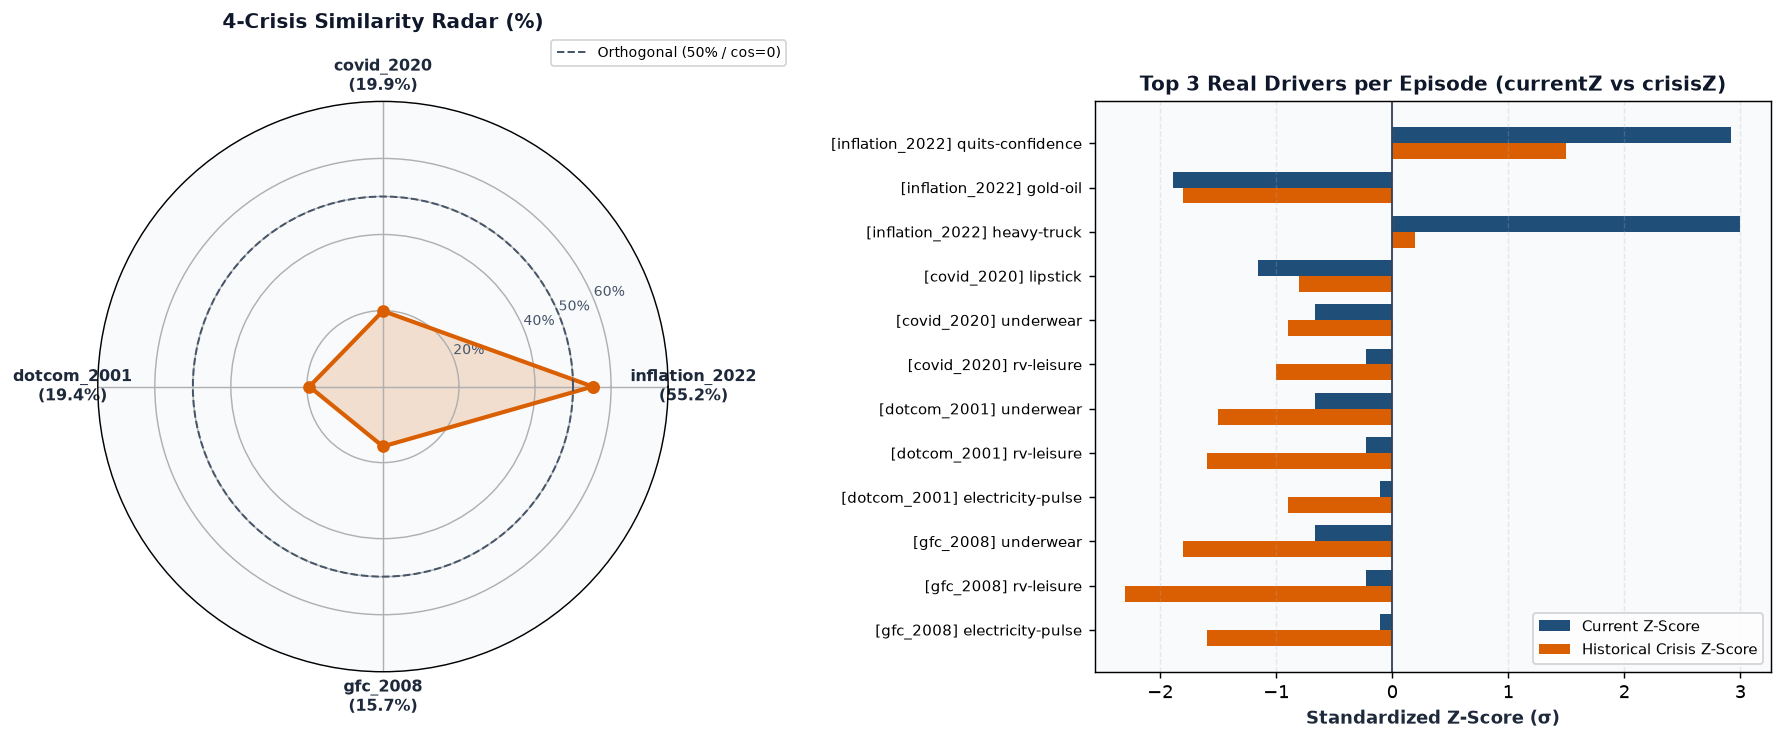

In [3]:
import numpy as np

fig = plt.figure(figsize=(14.0, 5.8), dpi=130, facecolor="#ffffff")
ax_radar = fig.add_subplot(1, 2, 1, projection="polar")
ax_drv = fig.add_subplot(1, 2, 2)

# Left: 4-Crisis Similarity Polar Radar
ordered_eps = list(df_episodes.itertuples(index=False))
ep_names = [f"{r.id}\n({r.similarityPct:.1f}%)" for r in ordered_eps]
vals = [float(r.similarityPct) for r in ordered_eps]
angles = np.linspace(0, 2 * np.pi, len(ordered_eps), endpoint=False).tolist()
vals_closed = vals + [vals[0]]
angles_closed = angles + [angles[0]]

ax_radar.set_facecolor("#f8fafc")
ax_radar.plot(angles_closed, vals_closed, color="#d95f02", lw=2.3, marker="o", markersize=6)
ax_radar.fill(angles_closed, vals_closed, color="#d95f02", alpha=0.18)

ref_angles = np.linspace(0, 2 * np.pi, 100)
ax_radar.plot(ref_angles, [50.0] * 100, ls="--", lw=1.1, color="#475569", label="Orthogonal (50% / cos=0)")
ax_radar.set_xticks(angles)
ax_radar.set_xticklabels(ep_names, fontsize=8.8, fontweight="bold", color="#1e293b")
ax_radar.set_ylim(0, 75)
ax_radar.set_yticks([20, 40, 50, 60])
ax_radar.set_yticklabels(["20%", "40%", "50%", "60%"], fontsize=7.8, color="#475569")
ax_radar.set_title("4-Crisis Similarity Radar (%)", fontsize=11, fontweight="bold", color="#0f172a", pad=16)
ax_radar.legend(loc="upper right", bbox_to_anchor=(1.22, 1.12), fontsize=8)

# Right: Top 12 real drivers currentZ vs crisisZ grouped bars (no zero-filling)
ax_drv.set_facecolor("#f8fafc")
y_idx = np.arange(len(df_drivers))
h = 0.36
ax_drv.barh(y_idx - h / 2, df_drivers["currentZ"], height=h, color="#1f4e78", label="Current Z-Score")
ax_drv.barh(y_idx + h / 2, df_drivers["crisisZ"], height=h, color="#d95f02", label="Historical Crisis Z-Score")
ax_drv.axvline(0, color="#334155", lw=1.0)
ax_drv.invert_yaxis()
ax_drv.set_yticks(y_idx)
ax_drv.set_yticklabels([f"[{r.episode}] {r.slug}" for r in df_drivers.itertuples(index=False)], fontsize=8.2)
ax_drv.set_xlabel("Standardized Z-Score (σ)", fontweight="bold", color="#1e293b")
ax_drv.set_title("Top 3 Real Drivers per Episode (currentZ vs crisisZ)", fontsize=11, fontweight="bold", color="#0f172a")
ax_drv.grid(True, axis="x", linestyle="--", alpha=0.25)
ax_drv.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="#ffffff")

plt.tight_layout()
plt.show()

## 3. Manufacturing Regime Summary (`PRO` / `ULTRA`: `/v1/regime-summary`)


In [4]:
reg = api_get(
    "/v1/regime-summary",
    "regime-summary-manufacturing.json",
    params={"category": "manufacturing"},
)
r_data = reg["data"]
print(
    f"Overall Regime: {r_data['overallRegime']} | "
    f"Avg Pro-Cyclical Index: {r_data['avgProCyclicalIndex']} | "
    f"Breadth: {r_data['breadth']}"
)

df_reg_indices = pd.DataFrame(list(r_data["indices"].values()))
df_reg_indices[["slug", "dataMonth", "indexValue", "zScore", "signal", "trend", "stance"]]

Overall Regime: Expansion | Avg Pro-Cyclical Index: 65.39 | Breadth: {'expansionCount': 2, 'neutralCount': 2, 'stressCount': 0, 'missingCount': 0}


,slug,dataMonth,indexValue,zScore,signal,trend,stance
0,cardboard,2026-09,51.49,0.0595,Neutral,stable,neutral
1,heavy-truck,2026-10,95.26,3.0000,Fleet Expansion,up,expansion
2,electricity-pulse,2026-10,47.32,-0.1072,Steady Load,stable,neutral
3,skyscraper,2026-09,67.49,0.7305,Commercial Boom,up,expansion


## 4. Heterogeneous Commodities Batch & Redaction Audit (`ULTRA`: `/v1/batch`)


In [5]:
batch = api_get(
    "/v1/batch",
    "batch-commodities.json",
    params={"category": "commodities", "limit": 6},
)

b_meta = batch.get("meta", {})
redacted_count = len(b_meta.get("redactedRawFields", []))
forbidden_prefixes = ("copper", "gold", "cocoa")

# Audit every observation record across all batch indices without naming redacted keys literally
bad_keys = []
for slug, rows in batch["data"]["indices"].items():
    for row in rows:
        for k in row.keys():
            if any(k.startswith(pref) and k.endswith("Price") for pref in forbidden_prefixes):
                bad_keys.append((slug, k))

assert not bad_keys, f"Unexpected raw price keys found: {bad_keys}"
print(f"Redaction audit passed: 0 prohibited spot-price keys in records (meta redacted field count = {redacted_count}).")

# Branch cleanly on '"countries" in row'
bigmac_rows = []
commodity_ts_rows = []
for slug, rows in batch["data"]["indices"].items():
    for row in rows:
        if "countries" in row:
            for c in row["countries"]:
                bigmac_rows.append({
                    "sourceDate": row.get("sourceDate"),
                    "fxAsOfDate": row.get("fxAsOfDate"),
                    "country": c.get("country"),
                    "currency": c.get("currency"),
                    "localPrice": c.get("localPrice"),
                    "usdPrice": c.get("usdPrice"),
                    "valuation": c.get("valuation"),
                    "status": c.get("status"),
                })
        else:
            commodity_ts_rows.append({
                "slug": slug,
                "dataMonth": row["dataMonth"],
                "indexValue": float(row["indexValue"]),
                "zScore": round(float(row["zScore"]), 4),
                "signal": row["signal"],
                "trend": row["trend"],
                "ratio": row.get("ratio"),
                "wtiOilPrice": row.get("wtiOilPrice"),
                "basketCost": row.get("basketCost"),
            })

df_bigmac_all = pd.DataFrame(bigmac_rows)
latest_bm_date = df_bigmac_all["sourceDate"].max()
df_bigmac_latest = (
    df_bigmac_all[df_bigmac_all["sourceDate"] == latest_bm_date]
    .drop_duplicates(subset=["country"], keep="first")
    .sort_values("valuation")
    .reset_index(drop=True)
)
df_comm = pd.DataFrame(commodity_ts_rows).sort_values(["slug", "dataMonth"]).reset_index(drop=True)

print(f"Latest Big Mac PPP Snapshot ({latest_bm_date}, {len(df_bigmac_latest)} countries):")
print(df_bigmac_latest[["country", "currency", "usdPrice", "valuation", "status"]].to_string(index=False))
df_comm.groupby("slug").tail(2)

Redaction audit passed: 0 prohibited spot-price keys in records (meta redacted field count = 2).
Latest Big Mac PPP Snapshot (2026-07-01, 15 countries):
         country currency  usdPrice  valuation      status
       🇹🇼 Taiwan      TWD      2.37     -61.96 undervalued
        🇮🇳 India      INR      2.55     -59.01 undervalued
        🇯🇵 Japan      JPY      3.15     -49.37 undervalued
    🇭🇰 Hong Kong      HKD      3.25     -47.69 undervalued
        🇨🇳 China      CNY      3.97     -36.19 undervalued
     🇹🇭 Thailand      THB      3.98     -36.03 undervalued
       🇧🇷 Brazil      BRL      4.02     -35.41 undervalued
  🇰🇷 South Korea      KRW      4.25     -31.73 undervalued
    🇦🇺 Australia      AUD      5.64      -9.27        fair
       🇨🇦 Canada      CAD      5.70      -8.29        fair
    🇸🇬 Singapore      SGD      5.78      -7.10        fair
🇺🇸 United States      USD      6.22       0.00    baseline
    🇪🇺 Euro area      EUR      6.80       9.28        fair
      🇬🇧 Britain     

,slug,dataMonth,indexValue,zScore,signal,trend,ratio,wtiOilPrice,basketCost
4,breakfast-inflation,2026-09,27.70,-0.9592,Deflationary Bargain,down,NaN,NaN,18.36
5,breakfast-inflation,2026-10,28.15,-0.9369,Deflationary Bargain,down,NaN,NaN,18.26
10,copper-gold,2026-08,87.32,1.9294,Industrial Boom,up,3.249,NaN,NaN
11,copper-gold,2026-09,92.47,2.5079,Industrial Boom,up,3.351,NaN,NaN
16,gold-oil,2026-09,19.34,-1.4282,Stagflation Shock,down,NaN,97.18,NaN
17,gold-oil,2026-10,13.10,-1.8926,Stagflation Shock,down,NaN,107.56,NaN


## 5. 13-Month Manufacturing Regime Backtest & Cross-Asset Alignment (Zero Synthetic Data)


13-Month Manufacturing Regime Timeline & Real Physical/Commodity Cross-Tab:
dataMonth  availCount  avgIndexValue                regime  regimeWeight  fwd1mCardboardIdxDelta  copperGoldRatio  wtiOilPrice
  2025-10           2          61.31             Expansion           1.0                  -26.14              NaN          NaN
  2025-11           4          37.83 Defensive Contraction           0.0                   22.69              NaN          NaN
  2025-12           4          50.85              Balanced           0.5                  -45.34              NaN          NaN
  2026-01           4          30.34 Defensive Contraction           0.0                   32.07              NaN          NaN
  2026-02           4          39.43 Defensive Contraction           0.0                   48.52              NaN          NaN
  2026-03           4          53.40              Balanced           0.5                  -24.74              NaN          NaN
  2026-04           4          48.4

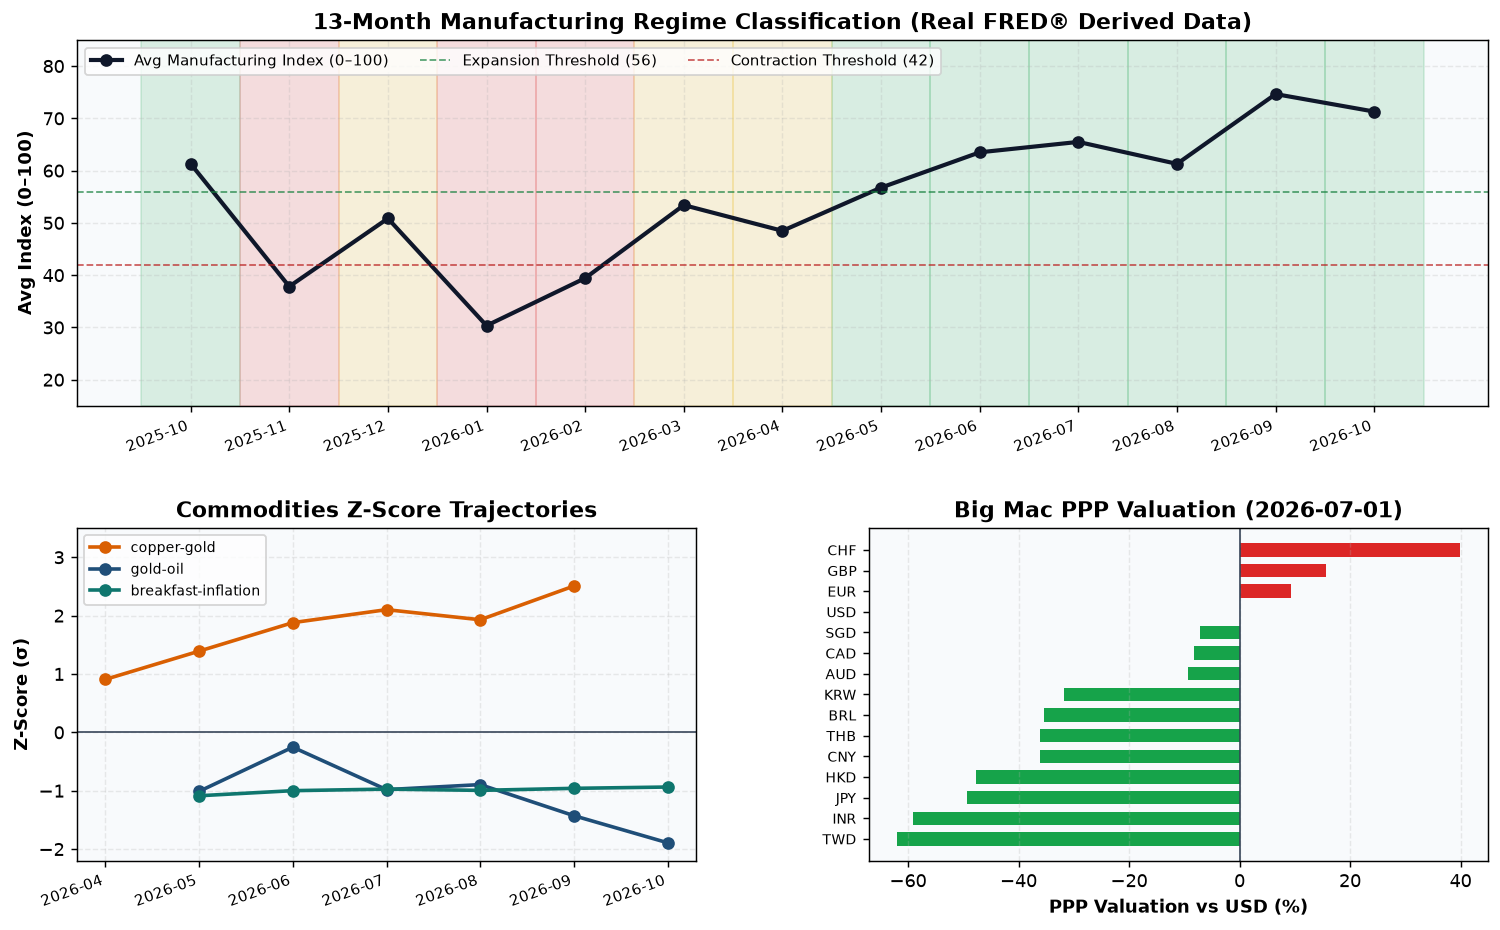

In [6]:
import math

cat_mfg = api_get("/v1/categories/manufacturing", "category-manufacturing.json", params={"limit": 12})
mfg_indices = cat_mfg["data"]["indices"]

all_months = sorted({r["dataMonth"] for rows in mfg_indices.values() for r in rows})
by_slug_month = {slug: {r["dataMonth"]: r for r in rows} for slug, rows in mfg_indices.items()}

# Reconstruct monthly Manufacturing Regime strictly using crisis-similarity.ts thresholds
bt_rows = []
for m in all_months:
    idx_vals = []
    exp_cnt = neu_cnt = str_cnt = 0
    for slug, mmap in by_slug_month.items():
        if m not in mmap:
            continue
        iv = float(mmap[m]["indexValue"])
        idx_vals.append(iv)
        if iv >= 55:
            exp_cnt += 1
        elif iv <= 45:
            str_cnt += 1
        else:
            neu_cnt += 1
    n_avail = len(idx_vals)
    avg_iv = round(sum(idx_vals) / n_avail, 2)
    stress_thr = max(2, math.ceil(n_avail * 0.55))
    exp_max_stress = math.floor(n_avail * 0.3)
    if avg_iv < 42 or str_cnt >= stress_thr:
        regime = "Defensive Contraction"
        weight = 0.0
    elif avg_iv >= 56 and str_cnt <= exp_max_stress:
        regime = "Expansion"
        weight = 1.0
    else:
        regime = "Balanced"
        weight = 0.5

    cb_row = by_slug_month["cardboard"].get(m, {})
    ht_row = by_slug_month["heavy-truck"].get(m, {})
    ep_row = by_slug_month["electricity-pulse"].get(m, {})

    bt_rows.append({
        "dataMonth": m,
        "availCount": n_avail,
        "avgIndexValue": avg_iv,
        "expansion": exp_cnt,
        "neutral": neu_cnt,
        "stress": str_cnt,
        "regime": regime,
        "regimeWeight": weight,
        "cardboardIdx": cb_row.get("indexValue"),
        "cardboardProdIdx": cb_row.get("productionIndex"),
        "heavyTruckYoY": ht_row.get("truckSalesYoY"),
        "electricPowerIp": ep_row.get("electricPowerIp"),
    })

df_regime_bt = pd.DataFrame(bt_rows)
df_regime_bt["fwd1mCardboardIdxDelta"] = df_regime_bt["cardboardIdx"].shift(-1) - df_regime_bt["cardboardIdx"]
df_regime_bt["fwd1mCardboardProdDelta"] = df_regime_bt["cardboardProdIdx"].shift(-1) - df_regime_bt["cardboardProdIdx"]

# Join overlapping real commodity indicators (2026-04..2026-10)
comm_piv = df_comm.pivot(index="dataMonth", columns="slug", values="zScore")
cg_ratio = df_comm[df_comm["slug"] == "copper-gold"].set_index("dataMonth")["ratio"]
wti_oil = df_comm[df_comm["slug"] == "gold-oil"].set_index("dataMonth")["wtiOilPrice"]

df_regime_bt["copperGoldRatio"] = df_regime_bt["dataMonth"].map(cg_ratio)
df_regime_bt["wtiOilPrice"] = df_regime_bt["dataMonth"].map(wti_oil)

print("13-Month Manufacturing Regime Timeline & Real Physical/Commodity Cross-Tab:")
print(df_regime_bt[["dataMonth", "availCount", "avgIndexValue", "regime", "regimeWeight", "fwd1mCardboardIdxDelta", "copperGoldRatio", "wtiOilPrice"]].to_string(index=False))

print("\nRegime-Conditional Summary (Real Observations Only):")
cond = df_regime_bt.groupby("regime", as_index=False).agg(
    months=("dataMonth", "count"),
    meanAvgIndex=("avgIndexValue", "mean"),
    meanFwd1mCardboardDelta=("fwd1mCardboardIdxDelta", "mean"),
    meanFwd1mProdDelta=("fwd1mCardboardProdDelta", "mean"),
)
print(cond.round(2).to_string(index=False))

# Visualization: Regime Timeline + Commodity Z-Scores & Big Mac PPP
fig = plt.figure(figsize=(14.0, 8.2), dpi=130, facecolor="#ffffff")
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1.0], hspace=0.35, wspace=0.28)
ax_top = fig.add_subplot(gs[0, :])
ax_bl = fig.add_subplot(gs[1, 0])
ax_br = fig.add_subplot(gs[1, 1])

# Top panel: 13-month Regime timeline
ax_top.set_facecolor("#f8fafc")
x_m = list(range(len(df_regime_bt)))
reg_colors = {"Expansion": "#16a34a", "Balanced": "#eab308", "Defensive Contraction": "#dc2626"}
for i, reg_name in enumerate(df_regime_bt["regime"]):
    ax_top.axvspan(i - 0.5, i + 0.5, color=reg_colors[reg_name], alpha=0.14)
ax_top.plot(x_m, df_regime_bt["avgIndexValue"], color="#0f172a", marker="o", lw=2.3, markersize=6, label="Avg Manufacturing Index (0–100)")
ax_top.axhline(56, ls="--", lw=1.0, color="#15803d", alpha=0.7, label="Expansion Threshold (56)")
ax_top.axhline(42, ls="--", lw=1.0, color="#b91c1c", alpha=0.7, label="Contraction Threshold (42)")
ax_top.set_xticks(x_m)
ax_top.set_xticklabels(df_regime_bt["dataMonth"], rotation=20, ha="right", fontsize=8.5)
ax_top.set_ylim(15, 85)
ax_top.set_ylabel("Avg Index (0–100)", fontweight="bold")
ax_top.set_title("13-Month Manufacturing Regime Classification (Real FRED® Derived Data)", fontweight="bold")
ax_top.grid(True, linestyle="--", alpha=0.25)
ax_top.legend(loc="upper left", ncol=3, fontsize=8.5, frameon=True, facecolor="#ffffff")

# Bottom-left: Commodity Z-Scores
ax_bl.set_facecolor("#f8fafc")
comm_months = sorted(df_comm["dataMonth"].unique())
xc = list(range(len(comm_months)))
for slug, col in [("copper-gold", "#d95f02"), ("gold-oil", "#1f4e78"), ("breakfast-inflation", "#0f766e")]:
    s = comm_piv[slug].reindex(comm_months)
    valid = s.notna()
    ax_bl.plot([i for i, ok in zip(xc, valid) if ok], s[valid], color=col, marker="o", lw=2.0, label=slug)
ax_bl.axhline(0, color="#334155", lw=0.9)
ax_bl.set_xticks(xc)
ax_bl.set_xticklabels(comm_months, rotation=20, ha="right", fontsize=8.2)
ax_bl.set_ylim(-2.2, 3.5)
ax_bl.set_ylabel("Z-Score (σ)", fontweight="bold")
ax_bl.set_title("Commodities Z-Score Trajectories", fontweight="bold")
ax_bl.grid(True, linestyle="--", alpha=0.25)
ax_bl.legend(loc="upper left", fontsize=8, frameon=True, facecolor="#ffffff")

# Bottom-right: Big Mac PPP Valuation %
ax_br.set_facecolor("#f8fafc")
bm_plot = df_bigmac_latest[df_bigmac_latest["valuation"].notna()].copy()
bm_cols = ["#16a34a" if v < 0 else ("#dc2626" if v > 0 else "#475569") for v in bm_plot["valuation"]]
ax_br.barh(range(len(bm_plot)), bm_plot["valuation"], color=bm_cols, height=0.65)
ax_br.axvline(0, color="#334155", lw=0.9)
ax_br.set_yticks(range(len(bm_plot)))
ax_br.set_yticklabels(bm_plot["currency"], fontsize=7.8)
ax_br.set_xlabel("PPP Valuation vs USD (%)", fontweight="bold")
ax_br.set_title(f"Big Mac PPP Valuation ({latest_bm_date})", fontweight="bold")
ax_br.grid(True, axis="x", linestyle="--", alpha=0.25)

plt.show()

## 6. Compliance, Attributions & Final Integrity Verification


In [7]:
# Verify zero prohibited raw spot price columns exist in any DataFrame
for name, df in [("df_comm", df_comm), ("df_bigmac_latest", df_bigmac_latest), ("df_regime_bt", df_regime_bt)]:
    bad_cols = [c for c in df.columns if any(c.startswith(p) and c.endswith("Price") for p in forbidden_prefixes)]
    assert not bad_cols, f"Prohibited column in {name}: {bad_cols}"

print("DataFrame column integrity check: PASSED (0 prohibited spot-price columns).")
print("\nLicense:", b_meta.get("license"))
print("Attributions:")
for attr in b_meta.get("attributions", []):
    print(" -", attr)
print("\nDisclaimer:", b_meta.get("disclaimer"))

DataFrame column integrity check: PASSED (0 prohibited spot-price columns).

License: CC BY 4.0 (Stalter Derived Quantitative Output)
Attributions:
 - Contains local price data adapted from The Economist Big Mac Index dataset (CC BY 4.0).
 - This product uses the FRED® API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.
 - Contains commodity benchmark data adapted from World Bank Commodity Price Data (The Pink Sheet, CC BY 4.0).
 - Derived indices incorporate IMF Primary Commodity Price System series retrieved via FRED; IMF does not endorse this product.

Disclaimer: For macroeconomic, statistical, and quantitative research purposes only. Does not constitute investment advice, securities recommendations, or regulated advisory services.
